# Term premium ACM a 10 años — Chile (CMF)

Foco en el **term premium a 10 años** de tres curvas chilenas:

| Segmento | Curva |
|---|---|
| Soberano | `Gob CERO Pesos` |
| Bancario | `CORP Bancarios AAA` |
| Corporativo | `CORP AAA` |

Modelo: Adrian-Crump-Moench con 3 factores PCA, datos mensuales ene-2016 a jul-2026, tasa corta a 3 meses
(ver `analysis/README.md`). Se usan las salidas ya calculadas por `analysis/acm_term_premium.py`
(`outputs/term_premium_acm_full.csv`, plazo `10.0` = 3.600 días). Recalcular el modelo requiere
`nachometrics_unified` y `curva.parquet`, que no están en el repo.

Unidades: **puntos base (bps)**. Al final hay un anexo con la exploración del Excel de bonos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3, "grid.linewidth": .6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})

ROOT = Path.cwd() if (Path.cwd() / "cmf_bonos_flujos_emisiones.xlsx").exists() else Path.cwd().parent
XLSX = ROOT / "cmf_bonos_flujos_emisiones.xlsx"
OUT = ROOT / "analysis" / "outputs"

SEGS = ["Soberano", "Bancario", "Corporativo"]
# Color fijo por entidad (paleta categórica validada para daltonismo)
SEG_COLOR = {"Soberano": "#2a78d6", "Bancario": "#eb6834", "Corporativo": "#1baf7a"}
COLORS = {"bancario": SEG_COLOR["Bancario"], "corporativo": SEG_COLOR["Corporativo"]}  # usado en el anexo

def label_ends(ax, df, colors, names=None, fmt="{:+.0f}"):
    """Etiquetas directas en el último punto de cada serie, separadas para que no se pisen."""
    names = names or {}
    ends = sorted(((df[c].dropna().index[-1], df[c].dropna().iloc[-1], c) for c in df), key=lambda t: t[1])
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * 0.06
    ys = []
    for _, y, _ in ends:
        ys.append(max(y, ys[-1] + gap) if ys else y)
    for (x, y, c), ty in zip(ends, ys):
        ax.plot(x, y, "o", ms=7, color=colors[c], mec="white", mew=1.5, zorder=5)
        ax.annotate(f"{names.get(c, c)} {fmt.format(y)}", (x, y), xytext=(x + pd.DateOffset(months=3), ty),
                    textcoords="data", va="center", fontsize=9, color="#333")

## 1. Datos

In [2]:
full = pd.read_csv(OUT / "term_premium_acm_full.csv", parse_dates=["date"])
tenores = [c for c in full.columns if c not in ("date", "segmento", "curva")]

tp10 = full.pivot(index="date", columns="segmento", values="10.0")[SEGS].mul(100)   # pp -> bps
tp30 = full.pivot(index="date", columns="segmento", values="30.0")[SEGS].mul(100)
tp10.tail()

segmento,Soberano,Bancario,Corporativo
date,,,
2026-03-31,3.98,-14.39,-36.53
2026-04-30,-7.99,-8.19,-41.55
2026-05-31,-6.51,1.49,-46.03
2026-06-30,-0.19,9.08,-34.43
2026-07-31,1.53,3.34,-45.54


In [3]:
# Corporativo tiene meses faltantes (~2019-2021): ojo al comparar
tp10.isna().groupby(tp10.index.year).sum().loc[lambda d: d.sum(axis=1) > 0]

segmento,Soberano,Bancario,Corporativo
date,,,
2019,0,0,8
2020,0,0,12
2021,0,0,8


## 2. Resumen del TP a 10 años

In [4]:
def resumen(s):
    s = s.dropna()
    ult = s.iloc[-1]
    return pd.Series({
        "obs": len(s), "último (bps)": ult, "media": s.mean(), "desv. est.": s.std(),
        "mín": s.min(), "máx": s.max(),
        "percentil del último": (s <= ult).mean() * 100,
        "z-score del último": (ult - s.mean()) / s.std(),
        "cambio 12m": ult - s.asof(s.index[-1] - pd.DateOffset(months=12)),
        "% meses negativo": (s < 0).mean() * 100,
    })

res10 = tp10.apply(resumen).T
res10

,obs,último (bps),media,desv. est.,mín,máx,percentil del último,z-score del último,cambio 12m,% meses negativo
segmento,,,,,,,,,,
Soberano,127.00,1.53,-9.59,16.94,-53.37,21.51,73.23,0.66,0.40,67.72
Bancario,127.00,3.34,-0.08,12.23,-34.82,27.31,62.20,0.28,4.81,52.76
Corporativo,99.00,-45.54,-28.90,24.11,-86.19,52.28,23.23,-0.69,-4.08,88.89


In [5]:
# Diagnósticos del modelo ACM (comunes a todos los plazos de cada curva)
diag = pd.read_csv(OUT / "term_premium_acm_summary.csv").set_index("segmento")
diag[["curva", "obs_mensuales", "var_explicada", "eig_max_Q", "rmse_precio_bps"]]

,curva,obs_mensuales,var_explicada,eig_max_Q,rmse_precio_bps
segmento,,,,,
Soberano,Gob CERO Pesos,127,1.00,1.00,4.73
Bancario,CORP Bancarios AAA,127,0.99,1.00,21.50
Corporativo,CORP AAA,99,0.98,1.00,25.11


## 3. Evolución

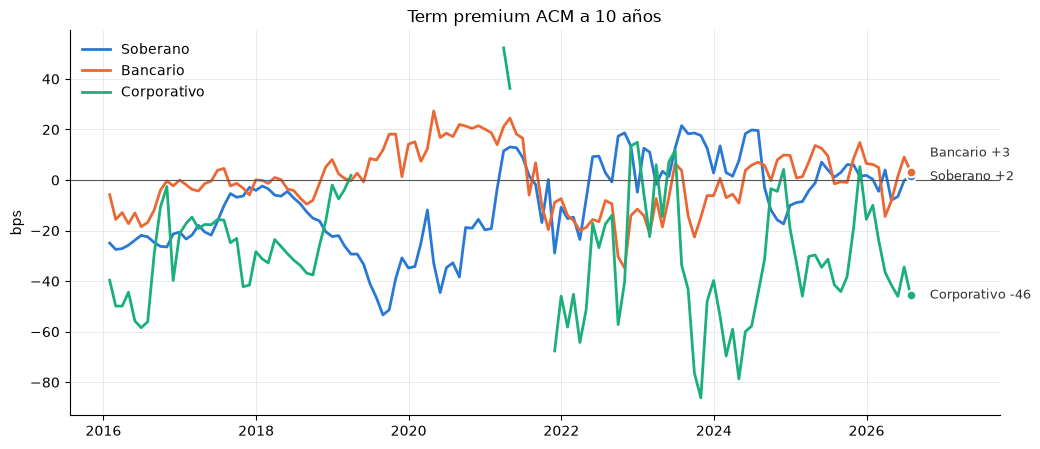

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for seg in SEGS:
    ax.plot(tp10.index, tp10[seg], color=SEG_COLOR[seg], label=seg)
label_ends(ax, tp10, SEG_COLOR)
ax.axhline(0, color="#555", lw=.8)
ax.set_title("Term premium ACM a 10 años"); ax.set_ylabel("bps"); ax.legend(loc="upper left", frameon=False)
ax.set_xlim(right=tp10.index[-1] + pd.DateOffset(months=14));

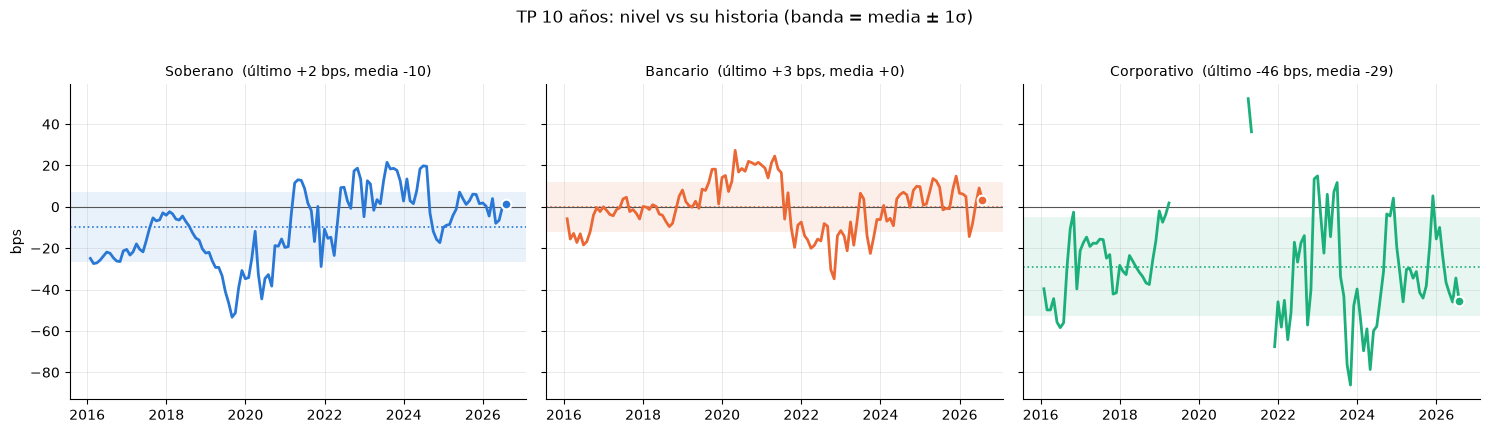

In [7]:
# Small multiples: cada segmento con su media muestral y banda ±1 desv. est.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, seg in zip(axes, SEGS):
    s = tp10[seg]
    m, sd = s.mean(), s.std()
    ax.axhspan(m - sd, m + sd, color=SEG_COLOR[seg], alpha=.10, lw=0)
    ax.axhline(m, color=SEG_COLOR[seg], ls=":", lw=1.2)
    ax.axhline(0, color="#555", lw=.8)
    ax.plot(s.index, s, color=SEG_COLOR[seg])
    ax.plot(s.dropna().index[-1], s.dropna().iloc[-1], "o", ms=7, color=SEG_COLOR[seg], mec="white", mew=1.5)
    ax.set_title(f"{seg}  (último {s.dropna().iloc[-1]:+.0f} bps, media {round(m) + 0:+d})", fontsize=10)
axes[0].set_ylabel("bps")
fig.suptitle("TP 10 años: nivel vs su historia (banda = media ± 1σ)", y=1.02)
plt.tight_layout()

In [8]:
# Promedio anual (bps)
anual10 = tp10.groupby(tp10.index.year).mean()
anual10.index.name = "año"
anual10.style.format("{:+.0f}").background_gradient(cmap="RdBu", vmin=-50, vmax=50, axis=None)

segmento,Soberano,Bancario,Corporativo
año,,,
2016,-24,-10,-38
2017,-13,-1,-23
2018,-10,-2,-27
2019,-36,+7,+2
2020,-27,+18,+nan
2021,-3,+6,-6
2022,+0,-17,-30
2023,+11,-10,-29
2024,+2,+2,-40


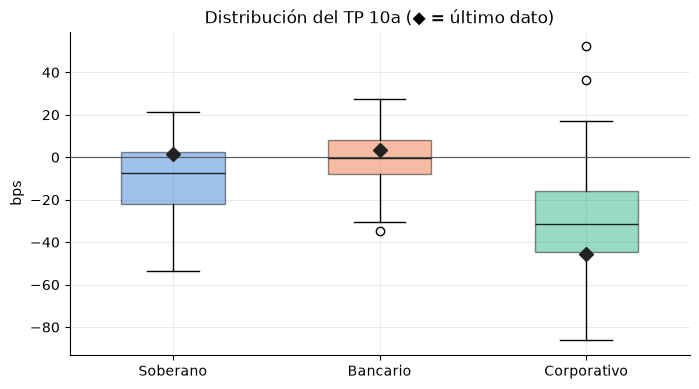

In [9]:
# Distribución mensual por segmento
fig, ax = plt.subplots(figsize=(8, 4.2))
data = [tp10[s].dropna() for s in SEGS]
bp = ax.boxplot(data, tick_labels=SEGS, patch_artist=True, widths=.5, medianprops={"color": "#222"})
for patch, s in zip(bp["boxes"], SEGS):
    patch.set_facecolor(SEG_COLOR[s]); patch.set_alpha(.45)
for i, s in enumerate(SEGS, 1):
    ax.plot(i, tp10[s].dropna().iloc[-1], "D", color="#222", ms=7, zorder=5)
ax.axhline(0, color="#555", lw=.8)
ax.set_title("Distribución del TP 10a (◆ = último dato)"); ax.set_ylabel("bps");

## 4. Spreads entre segmentos

,obs,último (bps),media,desv. est.,mín,máx,percentil del último
Bancario − Soberano,127.00,1.81,9.51,23.59,-53.49,69.48,31.50
Corporativo − Soberano,99.00,-47.07,-23.37,29.26,-103.80,50.52,16.16
Corporativo − Bancario,99.00,-48.88,-25.35,21.37,-71.47,31.11,11.11


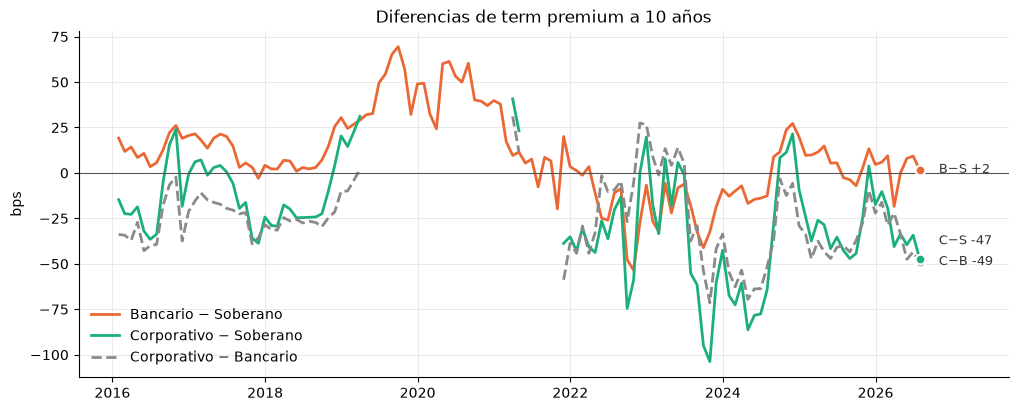

In [10]:
spr10 = pd.DataFrame({
    "Bancario − Soberano": tp10["Bancario"] - tp10["Soberano"],
    "Corporativo − Soberano": tp10["Corporativo"] - tp10["Soberano"],
    "Corporativo − Bancario": tp10["Corporativo"] - tp10["Bancario"],
})
spr_color = {"Bancario − Soberano": SEG_COLOR["Bancario"], "Corporativo − Soberano": SEG_COLOR["Corporativo"],
             "Corporativo − Bancario": "#8a8a8a"}

fig, ax = plt.subplots(figsize=(12, 4.5))
for c in spr10:
    ax.plot(spr10.index, spr10[c], color=spr_color[c], label=c, ls="--" if c.endswith("Bancario") else "-")
label_ends(ax, spr10, spr_color, names={"Bancario − Soberano": "B−S", "Corporativo − Soberano": "C−S",
                                        "Corporativo − Bancario": "C−B"})
ax.axhline(0, color="#555", lw=.8)
ax.set_title("Diferencias de term premium a 10 años"); ax.set_ylabel("bps"); ax.legend(frameon=False, loc="lower left")
ax.set_xlim(right=spr10.index[-1] + pd.DateOffset(months=14))
spr10.apply(resumen).T[["obs", "último (bps)", "media", "desv. est.", "mín", "máx", "percentil del último"]]

In [11]:
# Correlaciones: niveles y cambios mensuales
pd.concat({"niveles": tp10.corr(), "cambios mensuales": tp10.diff().corr()}, axis=1).round(2)

niveles                      cambios mensuales           \
segmento    Soberano Bancario Corporativo          Soberano Bancario   
segmento                                                               
Soberano        1.00    -0.29       -0.10              1.00    -0.14   
Bancario       -0.29     1.00        0.46             -0.14     1.00   
Corporativo    -0.10     0.46        1.00             -0.22     0.61   

                         
segmento    Corporativo  
segmento                 
Soberano          -0.22  
Bancario           0.61  
Corporativo        1.00

## 5. 10 años vs 30 años

¿Cuánto del premio está en el tramo 10a y cuánto se agrega entre 10a y 30a? La pendiente
`TP30 − TP10` mide el premio extra (aquí negativo) de ir al tramo muy largo.

,"corr(TP10, TP30)",TP30−TP10 último,TP30−TP10 media
Soberano,0.44,-102.52,-101.47
Bancario,-0.70,-264.26,-255.59
Corporativo,-0.97,-66.08,-108.99


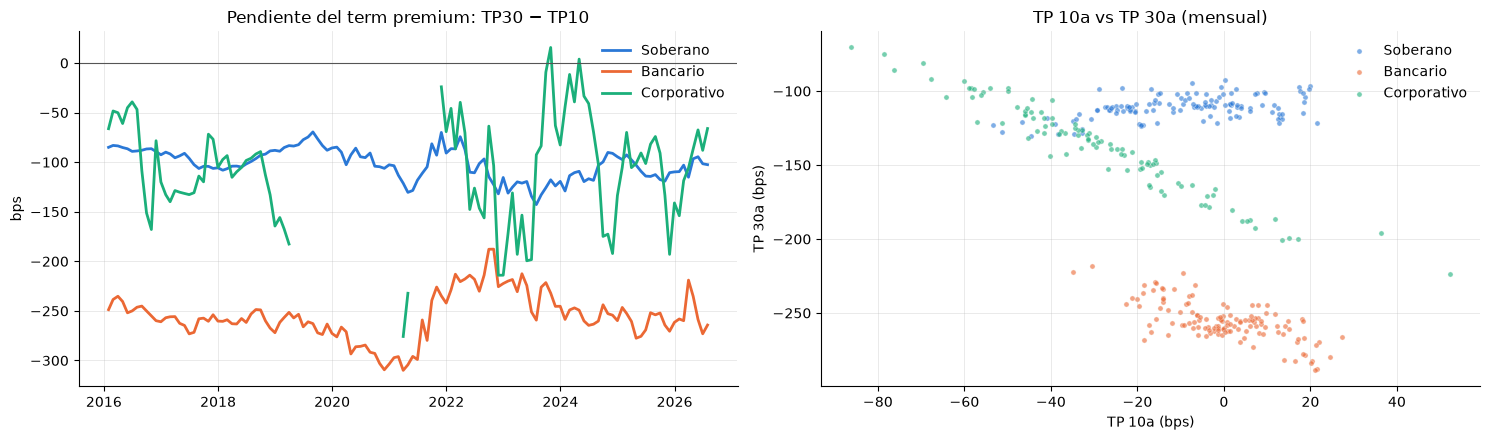

In [12]:
slope = tp30 - tp10
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for seg in SEGS:
    axes[0].plot(slope.index, slope[seg], color=SEG_COLOR[seg], label=seg)
    axes[1].scatter(tp10[seg], tp30[seg], s=14, color=SEG_COLOR[seg], alpha=.6, label=seg, edgecolor="white", lw=.4)
axes[0].axhline(0, color="#555", lw=.8)
axes[0].set_title("Pendiente del term premium: TP30 − TP10"); axes[0].set_ylabel("bps"); axes[0].legend(frameon=False)
axes[1].set_title("TP 10a vs TP 30a (mensual)"); axes[1].set_xlabel("TP 10a (bps)"); axes[1].set_ylabel("TP 30a (bps)")
axes[1].legend(frameon=False)
plt.tight_layout()

pd.DataFrame({"corr(TP10, TP30)": [tp10[s].corr(tp30[s]) for s in SEGS],
              "TP30−TP10 último": [slope[s].dropna().iloc[-1] for s in SEGS],
              "TP30−TP10 media": [slope[s].mean() for s in SEGS]}, index=SEGS)

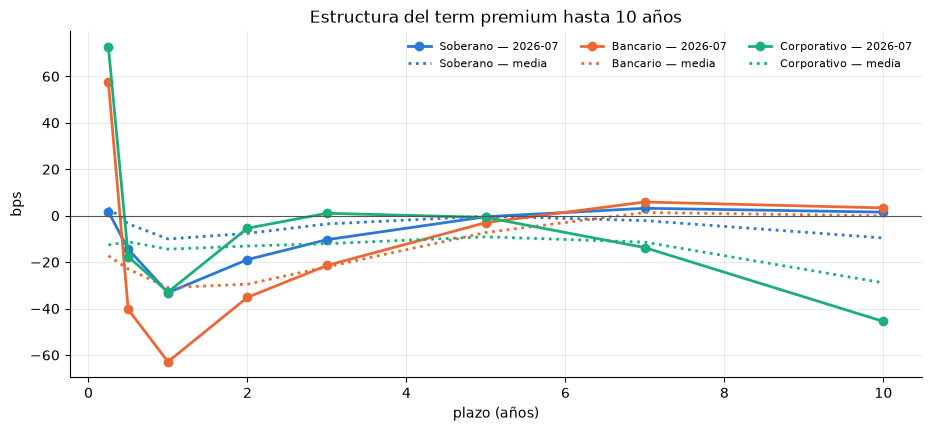

In [13]:
# Tramo 0-10 años de la estructura del TP: último dato vs media muestral
cortos = [t for t in tenores if float(t) <= 10]
x = [float(t) for t in cortos]
fig, ax = plt.subplots(figsize=(11, 4.5))
for seg in SEGS:
    g = full[full["segmento"] == seg]
    last = g.loc[g["date"].idxmax(), cortos].astype(float) * 100
    mean = g[cortos].astype(float).mean() * 100
    ax.plot(x, last.values, marker="o", ms=6, color=SEG_COLOR[seg], label=f"{seg} — {g['date'].max():%Y-%m}")
    ax.plot(x, mean.values, ls=":", color=SEG_COLOR[seg], label=f"{seg} — media")
ax.axhline(0, color="#555", lw=.8)
ax.set_title("Estructura del term premium hasta 10 años"); ax.set_xlabel("plazo (años)"); ax.set_ylabel("bps")
ax.legend(ncol=3, fontsize=8, frameon=False);

## 6. Lectura

- **A 10 años el premio es casi nulo en soberano y bancario** (≈ 0 bps al cierre de jul-2026, media muestral −10 y 0 bps).
  Todo el premio fuertemente negativo que aparece a 30 años se acumula **entre 10 y 30 años**.
- **El corporativo AAA es el único con premio a 10a claramente negativo** (≈ −45 bps al cierre, media ≈ −29 bps,
  negativo la gran mayoría de los meses) y se ubica bajo su propia media: el spread corporativo−soberano a 10a está ensanchado.
- **El soberano se movió de premio negativo (2016–2020) a ≈ 0 desde 2022**, coherente con el ciclo de alzas de tasas
  y la mayor incertidumbre inflacionaria; bancario y corporativo bajaron en 2022 y luego se recuperaron.
- Los premios por segmento están **poco correlacionados** (incluso negativa soberano–bancario en niveles):
  la dinámica a 10a responde más a factores propios de cada curva que a un factor común.
- **TP10 y TP30 se mueven en sentido opuesto** en bancario (corr ≈ −0,7) y corporativo (≈ −0,97): con 3 factores PCA
  el premio "rota" en torno a un plazo intermedio, así que un TP10 más alto viene con un TP30 más negativo.
  En soberano la correlación es positiva (≈ 0,4) y la pendiente TP30−TP10 es muy estable (≈ −100 bps).
- La serie corporativa tiene meses faltantes 2019–2021 y un par de datos aislados en 2021 (≈ +50 bps) que parecen
  ruido de una curva poco poblada; conviene no leerlos como señal.
- Cautela: muestra corta (~127 meses, 99 en corporativo con hueco 2019–2021), 3 factores; el **nivel** es sensible a la
  especificación, los cambios y spreads son más robustos.

---
# Anexo — Datos de bonos (`cmf_bonos_flujos_emisiones.xlsx`)

Exploración de flujos pagados y emisiones de bonos bancarios y corporativos (sin cambios respecto de la versión anterior).

In [14]:
xl = pd.read_excel(XLSX, sheet_name=None)
flujos, emis = xl["FLUJOS"], xl["EMISIONES"]

# Normalizar etiquetas de moneda (vienen con distintas grafías según la fuente)
MONEDA = {"U.F.": "UF", "UF": "UF", "Moneda Nacional": "CLP", "$": "CLP",
          "Dolar EEUU": "USD", "US$": "USD"}
for d in (flujos, emis):
    d["moneda"] = d["moneda_emision"].map(MONEDA).fillna("s/i")

print("FLUJOS", flujos.shape, "| EMISIONES", emis.shape)
flujos.head()

FLUJOS (27012, 14) | EMISIONES (11357, 21)


,fuente,emisor,serie,nro_inscripcion,periodo_reporte,fecha_flujo,regla_fecha,tipo_evento,interes_pagado_clp,amortizacion_pagada_clp,moneda_emision,fecha_vencimiento,nemo,moneda
0,bancario,Banco Bice,36,13/96,2015-01,2015-01-01,dia_vencimiento,cupon_y_amortizacion,"1,070,909.00","9,235,163.00",U.F.,2016-07-01,NaN,UF
1,bancario,Banco Bice,49,12/2010,2015-01,2015-01-01,dia_vencimiento,cupon,"507,933,938.00",0.00,U.F.,2035-07-01,NaN,UF
2,bancario,Banco Bice,50,05/2011,2015-01,2015-01-01,dia_vencimiento,cupon,"2,100,000.00",0.00,Dolar EEUU,2016-07-01,NaN,USD
3,bancario,Banco Bilbao Vizcaya Argentaria. Chile,A,01/2004,2015-01,2015-01-01,dia_vencimiento,cupon,"1,310,247,475.00",0.00,U.F.,2027-12-01,NaN,UF
4,bancario,Banco Bilbao Vizcaya Argentaria. Chile,B7,02/97,2015-01,2015-01-01,dia_vencimiento,cupon,"101,956,375.00",0.00,U.F.,2018-03-01,NaN,UF


### A.1 Flujos pagados

In [15]:
flujos["total_pagado_clp"] = flujos[["interes_pagado_clp", "amortizacion_pagada_clp"]].sum(axis=1)
flujos["anio"] = flujos["fecha_flujo"].dt.year

resumen = (flujos.groupby("fuente")
           .agg(emisores=("emisor", "nunique"), series=("serie", "nunique"), registros=("serie", "size"),
                desde=("fecha_flujo", "min"), hasta=("fecha_flujo", "max"),
                interes_MMM=("interes_pagado_clp", lambda s: s.sum() / 1e12),
                amortizacion_MMM=("amortizacion_pagada_clp", lambda s: s.sum() / 1e12)))
resumen  # montos en billones de CLP (1e12)

,emisores,series,registros,desde,hasta,interes_MMM,amortizacion_MMM
fuente,,,,,,,
bancario,22,583,18741,2015-01-01,2026-04-25,144.91,16.98
corporativo,314,100,8271,2016-01-01,2026-05-31,31.62,86.68


In [16]:
pd.crosstab(flujos["tipo_evento"], flujos["fuente"], margins=True)

fuente,bancario,corporativo,All
tipo_evento,,,
amortizacion,5,159,164
cupon,15442,5479,20921
cupon_y_amortizacion,3164,2577,5741
vencimiento_final,130,56,186
All,18741,8271,27012


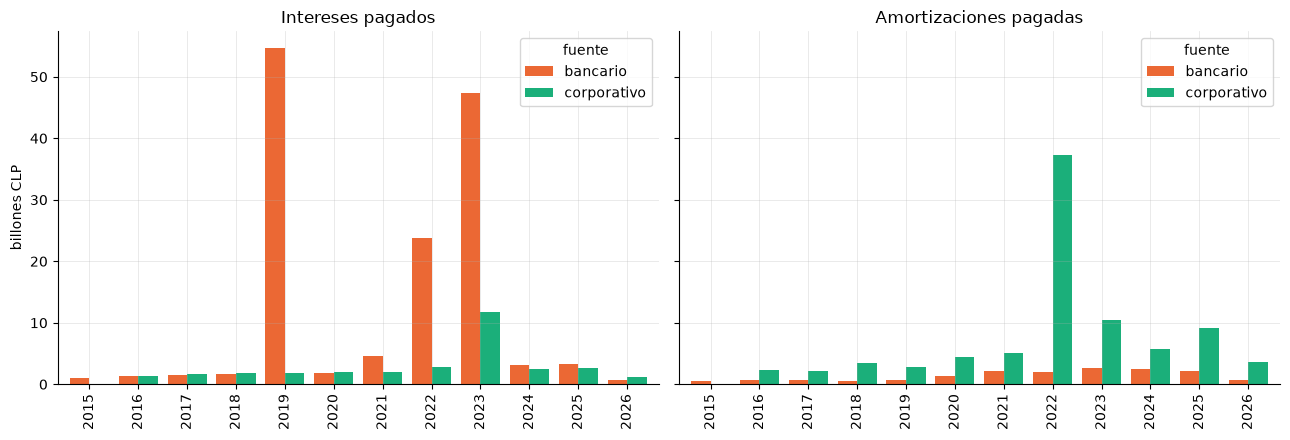

In [17]:
anual = (flujos.groupby(["anio", "fuente"])[["interes_pagado_clp", "amortizacion_pagada_clp"]]
         .sum().div(1e12).unstack("fuente"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col, title in zip(axes, ["interes_pagado_clp", "amortizacion_pagada_clp"], ["Intereses pagados", "Amortizaciones pagadas"]):
    anual[col].plot.bar(ax=ax, color=[COLORS[c] for c in anual[col].columns], width=.8)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("billones CLP")
plt.tight_layout()

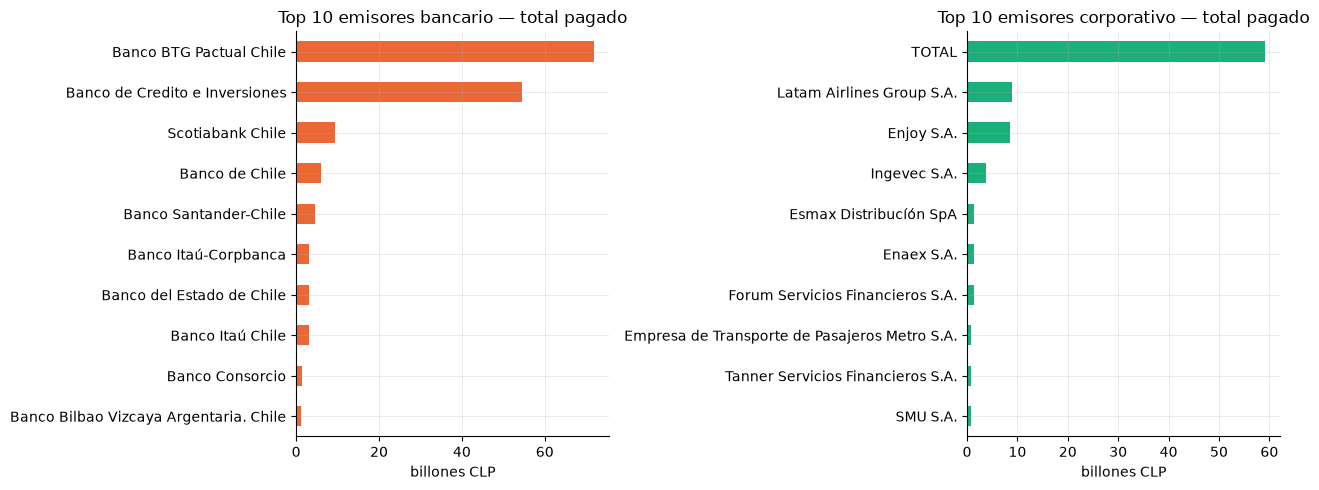

In [18]:
top = (flujos.groupby(["fuente", "emisor"])["total_pagado_clp"].sum().div(1e12)
       .sort_values(ascending=False).groupby(level=0).head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f in zip(axes, ["bancario", "corporativo"]):
    top[f].sort_values().plot.barh(ax=ax, color=COLORS[f])
    ax.set_title(f"Top 10 emisores {f} — total pagado"); ax.set_xlabel("billones CLP"); ax.set_ylabel("")
plt.tight_layout()

### A.2 Emisiones y colocaciones

**Calidad de datos (corporativo):** la hoja trae ~15 filas que son notas al pie del reporte CMF (`(1) CORRESPONDE…`, `*VALOR U.F.(…)=`) y se eliminan. Además, en corporativo `plazo` viene vacío y la tasa está en `tasa_emision_pct` (no en `tasa_colocacion_pct`), así que se construyen campos comunes: `tasa_pct` y `plazo_meses` (vencimiento − emisión/inscripción).

In [19]:
notas = emis["emisor"].astype(str).str.match(r"^\s*[(*]")
print("filas de notas al pie eliminadas:", notas.sum())
emis = emis[~notas].copy()

emis["tasa_pct"] = emis["tasa_colocacion_pct"].where(emis["tasa_colocacion_pct"] > 0, emis["tasa_emision_pct"])
emis.loc[~emis["tasa_pct"].between(0.01, 25), "tasa_pct"] = np.nan   # fuera de rango = no informado / error de unidad

inicio = emis["fecha_emision_nominal"].fillna(emis["fecha_inscripcion"])
plazo_calc = (emis["fecha_vencimiento"] - inicio).dt.days / 30.4375
emis["plazo_meses"] = emis["plazo"].fillna(plazo_calc.where(plazo_calc > 0))

emis.groupby("fuente")[["tasa_pct", "plazo_meses"]].count()

filas de notas al pie eliminadas: 15


,tasa_pct,plazo_meses
fuente,,
bancario,4329,4345
corporativo,4292,1614


In [20]:
emis["fecha_col"] = pd.to_datetime(emis["fecha_colocacion_periodo"], format="%Y-%m", errors="coerce")
emis["anio_col"] = emis["fecha_col"].dt.year.fillna(emis["fecha_emision_nominal"].dt.year)

pd.crosstab(emis["tipo_registro"], emis["fuente"], margins=True)

fuente,bancario,corporativo,All
tipo_registro,,,
aumento_colocacion,1250,523,1773
catalogo,3096,6473,9569
All,4346,6996,11342


In [21]:
pd.crosstab(emis["moneda"], emis["fuente"], margins=True)

fuente,bancario,corporativo,All
moneda,,,
CLP,815,604,1419
UF,3499,3196,6695
USD,31,58,89
s/i,1,3138,3139
All,4346,6996,11342


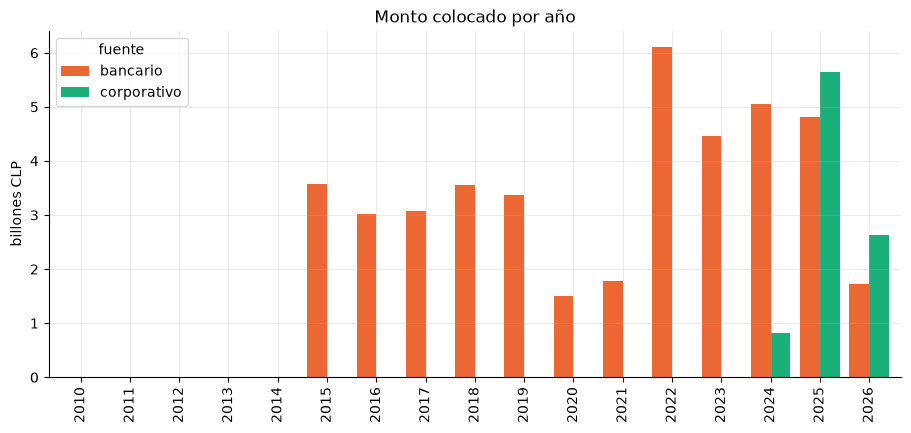

In [22]:
col_anual = (emis.groupby(["anio_col", "fuente"])["monto_colocado_periodo_clp"].sum()
             .div(1e12).unstack("fuente").loc[lambda d: d.index >= 2010])
ax = col_anual.plot.bar(color=[COLORS[c] for c in col_anual.columns], width=.8)
ax.set_title("Monto colocado por año"); ax.set_ylabel("billones CLP"); ax.set_xlabel("")
ax.set_xticklabels([int(x) for x in col_anual.index]);

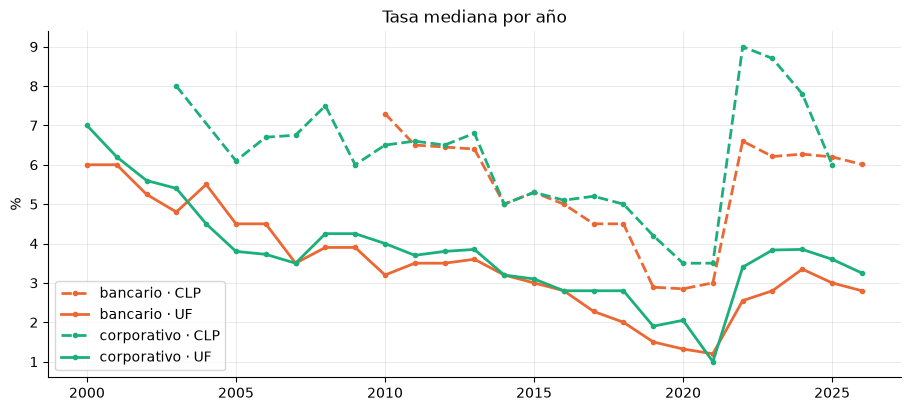

In [23]:
# Tasa (%) por año: bancario = colocaciones del período; corporativo = catálogo (año de inscripción)
emis["anio_ref"] = emis["fecha_col"].dt.year.fillna(emis["fecha_inscripcion"].dt.year)
tasa = (emis.dropna(subset=["tasa_pct", "anio_ref"])
        .query("moneda in ['UF', 'CLP'] and anio_ref >= 2000")
        .groupby(["anio_ref", "fuente", "moneda"])["tasa_pct"].median())

fig, ax = plt.subplots()
for (f, m), s in tasa.groupby(level=[1, 2]):
    if len(s) > 4:
        s.droplevel([1, 2]).plot(ax=ax, marker=".", label=f"{f} · {m}", color=COLORS[f], ls="-" if m == "UF" else "--")
ax.set_title("Tasa mediana por año"); ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend();

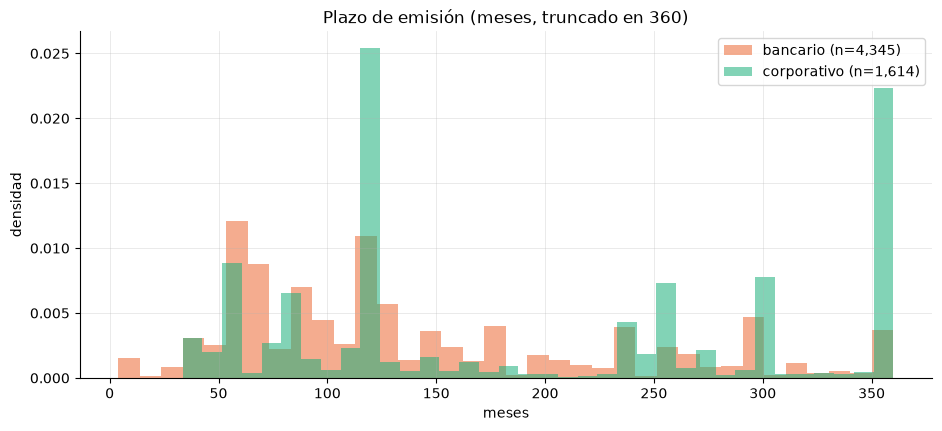

In [24]:
# Distribución del plazo (meses) al emitir
fig, ax = plt.subplots()
for f, g in emis.dropna(subset=["plazo_meses"]).groupby("fuente"):
    g["plazo_meses"].clip(upper=360).plot.hist(ax=ax, bins=36, alpha=.55, color=COLORS[f], label=f"{f} (n={len(g):,})", density=True)
ax.set_title("Plazo de emisión (meses, truncado en 360)"); ax.set_xlabel("meses"); ax.set_ylabel("densidad"); ax.legend();